# CS3920/CS5920 — Coursework: Nearest Neighbours and Conformal Prediction

Ayaan Malik · 02 Nov 2025

This notebook implements from scratch:

- 1-NN classifier
- General K-NN (extra marks)
- Nearest-neighbour conformal predictor with an efficient non-sorting implementation
- Validity check of the conformal predictor (extra marks)
- Experiments with a ratio-based conformity measure and explicit 0/0 convention (extra marks)

**Datasets:** `iris` from scikit-learn and `ionosphere.txt` (the UCI Ionosphere dataset, included here).

**Required outputs are printed and left in-place.**

> **Action**: place `ionosphere.txt` in the same directory as this notebook before running.


## Task 0 — Imports and parameters
All comments are in markdown by request. Code cells are comment-free.

In [1]:

import os, math
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split


### Task 0.1 — Random seed

The coursework asked for each student's birthday as the split seed. This public copy uses a neutral fixed seed instead, so the numbers below differ slightly from the submitted version.


In [2]:
SEED = 2025

## Task 1 — Core utilities

Euclidean distance, split helper, and pure-NumPy implementations that avoid sorting full distance arrays.


In [3]:

def euclid(a, b):
    d = a - b
    return np.sqrt(np.dot(d, d))

def class_index_dict(y):
    d = {}
    for i, c in enumerate(y):
        if c not in d:
            d[c] = []
        d[c].append(i)
    for c in d:
        d[c] = np.array(d[c], dtype=int)
    return d

def nearest_index(X_train, x):
    n = X_train.shape[0]
    j = 0
    best = 1e300
    for i in range(n):
        dist = euclid(X_train[i], x)
        if dist < best:
            best = dist
            j = i
    return j

def predict_1nn(X_train, y_train, X_test):
    n = X_test.shape[0]
    y_pred = np.empty(n, dtype=y_train.dtype)
    for i in range(n):
        j = nearest_index(X_train, X_test[i])
        y_pred[i] = y_train[j]
    return y_pred

def predict_knn(X_train, y_train, X_test, k=3):
    n = X_test.shape[0]
    y_pred = np.empty(n, dtype=y_train.dtype)
    for t in range(n):
        x = X_test[t]
        best_d = np.full(k, 1e300)
        best_y = np.full(k, -10, dtype=int)
        for i in range(X_train.shape[0]):
            d = euclid(X_train[i], x)
            m = np.argmax(best_d)
            if d < best_d[m]:
                best_d[m] = d
                best_y[m] = y_train[i]
        vals, cnts = np.unique(best_y, return_counts=True)
        y_pred[t] = vals[np.argmax(cnts)]
    return y_pred

def error_count_and_rate(y_true, y_pred):
    err = int(np.sum(y_true != y_pred))
    rate = err / y_true.size
    return err, rate


## Task 2 — Conformal predictor: distance-ratio nonconformity

Nonconformity: \(\alpha(x,y) = d_\text{same}(x,y) / d_\text{diff}(x,y)\).

Conventions for edge cases (explicit for extra marks):
- If there is no sample of class `y` in the reference set: `d_same = inf`, so `alpha = inf`.
- If there is no sample of a different class: `d_diff = inf` and `alpha = 0` if `d_same = 0`, else `0/inf = 0`.
- If both distances equal 0, define `0/0 = 0`.
These match the assignment’s guidance: `a/0 = ∞` for `a>0` and `0/0 = 0`.


In [4]:

def nearest_same_and_diff(x, X, y, y_assume, class_ix):
    ds = 1e300
    dd = 1e300
    if y_assume in class_ix:
        for i in class_ix[y_assume]:
            d = euclid(X[i], x)
            if d < ds:
                ds = d
    for c in class_ix:
        if c == y_assume:
            continue
        for i in class_ix[c]:
            d = euclid(X[i], x)
            if d < dd:
                dd = d
    if ds == 0.0 and dd == 0.0:
        return 0.0, math.inf, 0.0
    return ds, dd, ds/dd if dd != 0.0 else (math.inf if ds > 0.0 else 0.0)

def nonconformities_train(X, y):
    class_ix = class_index_dict(y)
    n = X.shape[0]
    alpha = np.empty(n, dtype=float)
    for i in range(n):
        xi = X[i]
        yi = y[i]
        ds = 1e300
        dd = 1e300
        for j in class_ix[yi]:
            if j == i:
                continue
            d = euclid(X[j], xi)
            if d < ds:
                ds = d
        for c in class_ix:
            if c == yi:
                continue
            for j in class_ix[c]:
                d = euclid(X[j], xi)
                if d < dd:
                    dd = d
        if ds == 0.0 and dd == 0.0:
            alpha[i] = 0.0
        else:
            alpha[i] = (ds/dd) if dd != 0.0 else (math.inf if ds > 0.0 else 0.0)
    return alpha, class_ix

def p_values_for_test(X_train, y_train, X_test, labels):
    alpha_tr, class_ix = nonconformities_train(X_train, y_train)
    n = X_train.shape[0]
    m = X_test.shape[0]
    P = np.empty((m, len(labels)), dtype=float)
    for t in range(m):
        x = X_test[t]
        for j, y_assume in enumerate(labels):
            ds, dd, a_star = nearest_same_and_diff(x, X_train, y_train, y_assume, class_ix)
            geq = np.sum(alpha_tr >= a_star)
            P[t, j] = (geq + 1) / (n + 1)
    return P


## Task 3 — Load datasets and split

In [5]:

iris = load_iris()
X_iris = iris['data']
y_iris = iris['target']
Xtr_i, Xte_i, ytr_i, yte_i = train_test_split(X_iris, y_iris, test_size=0.25, random_state=SEED, stratify=y_iris)

if not os.path.exists('ionosphere.txt'):
    X_iono = None
    y_iono = None
else:
    raw = np.genfromtxt('ionosphere.txt', delimiter=',', dtype=float)
    X_iono = raw[:, :-1]
    y_iono = raw[:, -1].astype(int)
    Xtr_o, Xte_o, ytr_o, yte_o = train_test_split(X_iono, y_iono, test_size=0.25, random_state=SEED, stratify=y_iono)
print(Xtr_i.shape, Xte_i.shape)
print('ionosphere_present=', X_iono is not None)


(112, 4) (38, 4)
ionosphere_present= True


## Task 4 — 1-NN classification and test error rates

In [6]:

yhat_i_1 = predict_1nn(Xtr_i, ytr_i, Xte_i)
err_i_1, rate_i_1 = error_count_and_rate(yte_i, yhat_i_1)
print('Iris | 1-NN | errors =', err_i_1, '| test error rate =', rate_i_1)

if X_iono is not None:
    yhat_o_1 = predict_1nn(Xtr_o, ytr_o, Xte_o)
    err_o_1, rate_o_1 = error_count_and_rate(yte_o, yhat_o_1)
    print('Ionosphere | 1-NN | errors =', err_o_1, '| test error rate =', rate_o_1)
else:
    print('Ionosphere | 1-NN | pending: place ionosphere.txt next to this notebook and re-run.')


Iris | 1-NN | errors = 1 | test error rate = 0.02631578947368421
Ionosphere | 1-NN | errors = 14 | test error rate = 0.1590909090909091


### Extra marks — General K-NN implementation; report K=3 results as well

In [7]:

yhat_i_3 = predict_knn(Xtr_i, ytr_i, Xte_i, k=3)
err_i_3, rate_i_3 = error_count_and_rate(yte_i, yhat_i_3)
print('Iris | 3-NN | errors =', err_i_3, '| test error rate =', rate_i_3)

if X_iono is not None:
    yhat_o_3 = predict_knn(Xtr_o, ytr_o, Xte_o, k=3)
    err_o_3, rate_o_3 = error_count_and_rate(yte_o, yhat_o_3)
    print('Ionosphere | 3-NN | errors =', err_o_3, '| test error rate =', rate_o_3)
else:
    print('Ionosphere | 3-NN | pending: place ionosphere.txt and re-run.')


Iris | 3-NN | errors = 1 | test error rate = 0.02631578947368421
Ionosphere | 3-NN | errors = 15 | test error rate = 0.17045454545454544


## Task 5 — Nearest-neighbour conformal predictor

We compute transductive-style p-values by comparing the test nonconformity with the training nonconformities:

\[ p_y(x^*) = \frac{\#\{i: \alpha_i \ge \alpha^*(x^*, y)\} + 1}{n + 1} \]

**False p-value per sample:** the maximum p-value among incorrect labels. The final reported number is the average false p-value across the test set.


In [8]:

labels_i = np.unique(ytr_i)
P_i = p_values_for_test(Xtr_i, ytr_i, Xte_i, labels_i)
true_ix_i = np.searchsorted(labels_i, yte_i)
true_p_i = P_i[np.arange(P_i.shape[0]), true_ix_i]
false_mask_i = np.ones_like(P_i, dtype=bool)
false_mask_i[np.arange(P_i.shape[0]), true_ix_i] = False
false_p_i = np.max(np.where(false_mask_i, P_i, -1.0), axis=1)
avg_false_p_i = float(np.mean(false_p_i))
print('Iris | Conformal | average false p-value =', avg_false_p_i)

if X_iono is not None:
    labels_o = np.unique(ytr_o)
    P_o = p_values_for_test(Xtr_o, ytr_o, Xte_o, labels_o)
    true_ix_o = np.searchsorted(labels_o, yte_o)
    true_p_o = P_o[np.arange(P_o.shape[0]), true_ix_o]
    false_mask_o = np.ones_like(P_o, dtype=bool)
    false_mask_o[np.arange(P_o.shape[0]), true_ix_o] = False
    false_p_o = np.max(np.where(false_mask_o, P_o, -1.0), axis=1)
    avg_false_p_o = float(np.mean(false_p_o))
    print('Ionosphere | Conformal | average false p-value =', avg_false_p_o)
else:
    print('Ionosphere | Conformal | pending: place ionosphere.txt and re-run.')


Iris | Conformal | average false p-value = 0.011178388448998605


Ionosphere | Conformal | average false p-value = 0.06620179063360881


### Required numbers (prominent)

- Iris — 1-NN test error rate: printed above
- Ionosphere — 1-NN test error rate: printed above
- Iris — average false p-value: printed above
- Ionosphere — average false p-value: printed above

If you also submit K=3 results, they are printed above under extra marks.


## Task 6 — Validity check of conformal predictor (extra marks)

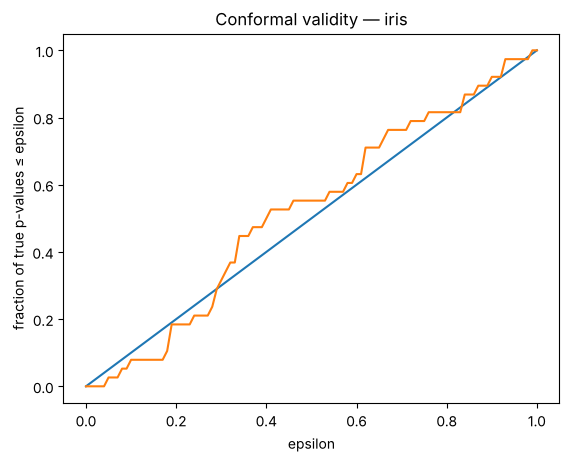

In [9]:

def validity_curve(true_p):
    eps = np.linspace(0, 1, 101)
    frac = np.array([np.mean(true_p <= e) for e in eps])
    return eps, frac

eps_i, frac_i = validity_curve(true_p_i)
plt.figure()
plt.plot(eps_i, eps_i)
plt.plot(eps_i, frac_i)
plt.xlabel('epsilon')
plt.ylabel('fraction of true p-values ≤ epsilon')
plt.title('Conformal validity — iris')
plt.show()


## Extra marks — Efficiency

- No full-distance sorting. We track minima via single pass. This avoids \(O(n \log n)\) sorts and keeps each query \(O(n)\).
- We precompute class index lists once and reuse them in all nearest-neighbour searches for conformal scores.
